# 10B — Three signature football stories

**Story 1 — Wide receiver: same speed, different development.** The pair is chosen by six declared criteria (`signature_stories.WR_CRITERIA`): stored twins with the split also matched · a distinguishable, repeatable, non-redundant feature · at least two features beyond their uncertainty · two tracked attempts each · a difference in mid-sprint or late speed development · largest contrast. The pair named in the brief (Ladd McConkey and Isaiah Bond) is used **only if it passes every criterion**; otherwise the strongest eligible WR pair is used and the failed criterion is reported.

**Story 2 — Same forty, different curve.** The 09D case of that type naming Anthony Bradford and Mason McCormick, validated (identical official forty, ≥ 1 distinguishable feature), else the first validated case of the type.

**Story 3 — The position-specific movement gap.** The position with the largest share of observed NFL exposure in demands the forty has no analogue of, among positions whose supported demand cells all have ≥ 30 athletes (`movement_gap.gap_position`).

**No NFL outcome or exposure value enters any selection.** Each story gets: a hero figure, a comparison card, a ≤ 100-word explanation, a technical interpretation, a scouting checklist, a 30-second narration, a provenance record and a no-data fallback. The application's Signature Stories page runs the same functions on the same mart.

**Prerequisites.** 09E (mart), 10A passed. **Writes.** figures `AM10B_*` under `reports/figures/advanced_movement/product_v1/`, `reports/milestone10/stories/*.md`, intelligence cards, `product_v1/signature_stories.json`.

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full'
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import os

import matplotlib.pyplot as plt
import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import final_figures as ff
from nflbdb.research.advanced_movement import intelligence_figures as ifg
from nflbdb.research.advanced_movement import milestone09_artifacts as m9
from nflbdb.research.advanced_movement import movement_gap as mg
from nflbdb.research.advanced_movement import product_kit as pk
from nflbdb.research.advanced_movement import scouting_interpretation as sin
from nflbdb.research.advanced_movement import signature_stories as ss
from nflbdb.research.advanced_movement.artifacts import ProductStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = ProductStore(cfg, controls)
MART = m9.mart_path(store)
m9.assert_valid(m9.validate_mart(MART))
T, EVID, MANIFEST = m9.load_mart(MART)
OUT = store.reports_dir / 'stories'
OUT.mkdir(parents=True, exist_ok=True)
C = T['combine_attempt_curves']

def _attempts(i):
    return C.filter(pl.col('nfl_id') == i).sort('attempt_order', 'frame').partition_by(['attempt_order'], as_dict=True, maintain_order=True).values()

def curves(i):
    return [(g['dist_yd'].to_numpy().astype(float), g['speed'].to_numpy().astype(float)) for g in _attempts(i)]

def curves_t(i):
    return [(g['t_s'].to_numpy().astype(float), g['dist_yd'].to_numpy().astype(float), g['speed'].to_numpy().astype(float)) for g in _attempts(i)]

def band(pos):
    B = T['position_curve_bands'].filter(pl.col('position_group') == pos).sort('dist_yd')
    return {'grid': B['dist_yd'].to_numpy(), 'q10': B['q10'].to_numpy(), 'q50': B['q50'].to_numpy(), 'q90': B['q90'].to_numpy(), 'n': int(B['n_runs'][0])} if B.height else None

PROF = {r['nfl_id']: r for r in T['prospect_profiles'].iter_rows(named=True)}
TW = T['stopwatch_twins'].to_dicts()
TWD = {t['pair_id']: t for t in TW}
BYPAIR = {}
for r in T['twin_differences'].sort('feature').iter_rows(named=True):
    BYPAIR.setdefault(r['pair_id'], []).append(r)
CLAIMS = {c['claim_id']: c for c in EVID.get('evidence_claims_08b6', [])}
DEM = T['nfl_movement_demands'].to_dicts()
PROV = {'mart': cfg.paths.rel(MART), 'mart_version': MANIFEST['mart_version'], 'mart_built_at': MANIFEST['built_at'], 'run_mode': controls.run_mode,
        'notebook': '10b_signature_football_stories.ipynb', 'engine_version': ss.VERSION}
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · mart built {MANIFEST["built_at"]}'))

**Run mode: `full`** (FULL) · mart built 2026-10-14T13:13:05Z

## 1 · Story 1 — selecting the wide-receiver pair

Every stored WR twin pair with the six criteria evaluated. The table is the audit trail of the choice.

In [3]:
WR_CAND = ss.wr_candidates(TW, BYPAIR, PROF)
display(pl.DataFrame(WR_CAND).head(15) if WR_CAND else 'no WR twin pair in this mart')
WR_PICK, WR_WHY = ss.select_wr_pair(WR_CAND)
pref = next((c for c in WR_CAND if c['preferred']), None)
display(Markdown(f'**Selection:** {WR_WHY}.' + ('' if pref is None else f"  \nPreferred pair criteria: " + ', '.join(f'{k} = {pref[k]}' for k, _ in ss.WR_CRITERIA[:5]))))

pair_id,name_a,name_b,forty_a,forty_b,attempts_a,attempts_b,n_distinguishable_usable,valid_match,feature_evidence,uncertainty_support,attempts,physical_interval,eligible,contrast,top_feature,preferred
str,str,str,f64,f64,i64,i64,i64,bool,bool,bool,bool,bool,bool,f64,str,bool
"""57155-59278""","""Ladd McConkey""","""Isaiah Bond""",4.39,4.39,2,2,3,true,true,true,true,true,true,8.950549,"""top_speed""",true
"""58338-59278""","""Jalen Royals""","""Isaiah Bond""",4.42,4.39,2,2,3,true,true,true,true,true,true,8.354818,"""top_speed""",false
"""59004-59278""","""Isaiah Neyor""","""Isaiah Bond""",4.4,4.39,2,2,2,true,true,true,true,true,true,8.051416,"""top_speed""",false
"""55938-57155""","""Jalin Hyatt""","""Ladd McConkey""",4.4,4.39,2,2,2,true,true,true,true,true,true,6.850147,"""top_speed""",false
"""55938-58514""","""Jalin Hyatt""","""Elijhah Badger""",4.4,4.43,2,2,2,true,true,true,true,true,true,6.78018,"""top_speed""",false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""56563-59278""","""Jacob Copeland""","""Isaiah Bond""",4.42,4.39,2,2,3,true,true,true,true,true,true,5.980663,"""top_speed""",false
"""57152-57153""","""Ricky Pearsall""","""Xavier Legette""",4.41,4.39,2,2,3,true,true,true,true,true,true,5.876513,"""speed_30yd""",false
"""55920-56118""","""Rashee Rice""","""Ronnie Bell""",4.51,4.54,2,2,3,true,true,true,true,true,true,5.660486,"""speed_20yd""",false


**Selection:** the pair named in the brief (Ladd McConkey and Isaiah Bond) passes all six criteria.  
Preferred pair criteria: valid_match = True, feature_evidence = True, uncertainty_support = True, attempts = True, physical_interval = True

## 2 · Story 2 — validating the same-forty case · Story 3 — choosing the movement-gap position

In [4]:
SF_CASE, SF_WHY = ss.select_same_forty(T['scouting_cases'].to_dicts(), TWD)
display(Markdown(f'**Same forty:** {SF_WHY}.'))
G = mg.gap_matrix(T['nfl_demand_registry'].to_dicts(), DEM, T['movement_matching_summary'].to_dicts())
GS = mg.gap_summary(G)
FOCUS = mg.gap_position(GS)
display(pl.DataFrame(GS))
msg = 'no position meets the support rule' if FOCUS is None else f"{FOCUS['position_group']} — {100 * FOCUS['share_not_measured']:.0f} % of its exposure index is in demands without a forty analogue"
display(Markdown(f'**Movement gap:** {msg}.'))

**Same forty:** the 09D case named in the brief: identical official forty and ≥ 1 distinguishable feature.

position_group,rate_direct,rate_partial,rate_not_measured,rate_unavailable,rate_total,share_not_measured,share_direct_or_partial,n_supported_demands,n_eligible_plays,min_athletes,n_not_measured,n_unavailable
str,f64,f64,i64,f64,f64,f64,f64,i64,i64,i64,i64,i64
"""DB""",99.560347,26.44804,0,84.108333,210.116719,0.0,0.599707,9,63914,72,0,5
"""DL""",106.731132,10.624863,0,51.835673,169.191668,0.0,0.693628,9,50363,22,0,6
"""OL""",81.405937,2.738932,0,10.762505,94.907374,0.0,0.8866,8,82806,29,0,6
"""TE""",102.387986,20.544067,0,132.865583,255.797637,0.0,0.480583,9,8124,17,0,6
"""WR""",98.338582,33.505267,0,133.198501,265.04235,0.0,0.497444,9,36836,68,0,5


**Movement gap:** WR — 0 % of its exposure index is in demands without a forty analogue.

## 3 · The three stories (every deliverable)

In [5]:
STORIES, SEL = {}, {'wr': WR_WHY, 'same_forty': SF_WHY, 'gap': 'largest exposure share without a forty analogue' if FOCUS else 'support rule not met'}
if WR_PICK:
    t = TWD[WR_PICK['pair_id']]
    STORIES['wr'] = ss.pair_story('wr', t, BYPAIR.get(t['pair_id'], []), PROF, DEM, CLAIMS, {**PROV, 'selection': WR_WHY})
if SF_CASE:
    t = TWD[SF_CASE['pair_id']]
    STORIES['same_forty'] = ss.pair_story('same_forty', t, BYPAIR.get(t['pair_id'], []), PROF, DEM, CLAIMS, {**PROV, 'selection': SF_WHY, 'case_id': SF_CASE['case_id']})
if FOCUS:
    STORIES['gap'] = ss.gap_story(FOCUS, G, CLAIMS, PROV)
for k in ('wr', 'same_forty', 'gap'):
    s = STORIES.get(k)
    display(Markdown(ss.story_markdown(s) if s else f'## {k}: not available\n\n{SEL[k]}'))
    if s:
        print(f'{k}: summary {pk.words(s["summary_100"])} words · narration {pk.words(s["narration_30s"])} words')

## Same speed, different development — Ladd McConkey and Isaiah Bond (WR)

**In 100 words.** Ladd McConkey and Isaiah Bond (WR) ran identical official forties of 4.39 s. Their 10 Hz tracking separates them on 3 of 8 measured features beyond measurement uncertainty; the largest is tracked top speed (p95): 10.93 yd/s versus 11.76 yd/s. The difference sits in late acceleration and high speed (above about 6 yd/s), mid-sprint speed development (about 4 to 8 yd/s). That makes it a specific question for film and a targeted test — not a verdict on either player, because no tracked Combine feature has shown NFL predictive value here.

**30-second narration.** Two WR prospects. Identical official forties of 4.39 s. The stopwatch calls them the same. Ten-hertz tracking does not: tracked top speed (p95), 10.93 yd/s against 11.76 yd/s, beyond measurement uncertainty. It sits in late acceleration and high speed (above about 6 yd/s). The Lab turns that into a film question and a targeted test. It does not say who will play better.

**Comparison card**

- position: WR
- names: Ladd McConkey · Isaiah Bond
- official forty: 4.39 · 4.39
- official ten: 1.52 · 1.51
- weight: 186.0 · 180.0
- tracked attempts: 2 · 2
- evidence tier: low · high
- distinguishable: 3 of 8 tested features
- phases: late acceleration and high speed (above about 6 yd/s) · mid-sprint speed development (about 4 to 8 yd/s)
- largest: tracked top speed (p95): 10.93 yd/s vs 11.76 yd/s

**Technical interpretation**

- Matching: stored 09C rule — same position, official forty within 0.03 s (|Δ| = 0.00 s), 10-yard split |Δ| = 0.01 s.
- tracked top speed (p95): 10.93 yd/s vs 11.76 yd/s, difference +0.84 yd/s [+0.65, +1.02] (z = +8.95); evidence status repeatable_beyond_official.
- speed at 30 yd: 10.87 yd/s vs 11.38 yd/s, difference +0.51 yd/s [+0.34, +0.67] (z = +5.88); evidence status repeatable_mostly_stopwatch.
- speed at 20 yd: 10.29 yd/s vs 10.62 yd/s, difference +0.34 yd/s [+0.17, +0.50] (z = +3.98); evidence status repeatable_mostly_stopwatch.
- Initial acceleration: band acceleration 2 → 4 yd/s 6.95 (Ladd McConkey) vs 5.23 (Isaiah Bond) yd/s², difference -1.72 [-3.05, -0.40] — inside its measurement uncertainty — not a difference.
- Early speed development: speed at 10 yd 9.28 (Ladd McConkey) vs 8.92 (Isaiah Bond) yd/s, difference -0.36 [-0.77, +0.06] — inside its measurement uncertainty — not a difference.
- Intermediate speed development: speed at 20 yd 10.29 (Ladd McConkey) vs 10.62 (Isaiah Bond) yd/s, difference +0.34 [+0.17, +0.50] — larger than its measurement uncertainty.
- Late sprint: speed at 30 yd 10.87 (Ladd McConkey) vs 11.38 (Isaiah Bond) yd/s, difference +0.51 [+0.34, +0.67] — larger than its measurement uncertainty.
- Maximum tracked speed: tracked top speed (p95) 10.93 (Ladd McConkey) vs 11.76 (Isaiah Bond) yd/s, difference +0.84 [+0.65, +1.02] — larger than its measurement uncertainty.
- Largely the same information as official testing: speed at 30 yd, speed at 20 yd.
- Uncertainty: each interval is ±1.96 standard errors of the difference built from both athletes' repeat-attempt variation; about 5 % of features would be called distinguishable by chance, and features of one run are correlated.
- C02: Speed development (time from 4 to 8 yd/s) is repeatable and only partly explained by the stopwatch — ICC 0.82 [0.78, 0.86]; R² on the stopwatch 0.65; atlas grade Provisional
- C04: Tracked top speed is largely the same information as official testing — R² on the stopwatch 0.87
- C08: TCN-B did NOT establish an improvement of held-out NFL sustained-acceleration prediction beyond official testing — Δ RMSE +0.0003 [-0.0008, +0.0015] (+0.16 % of the official-model error); interval includes 0
- C14: Primary football transfer comparison (engineered speed development beyond official testing) — M2 versus M1 on FO01.S0: Δ RMSE -0.0007 [-0.0093, +0.0082], linkage permutation p 0.345 — not established (interval includes 0) (EXPLORATORY — source semantics inferred; definitions locked)
- C17: Combine tracking characteristics that stay repeatable after official tests are accounted for — repeatable beyond official tests: tracked top speed (p95), speed development 4 → 8 yd/s, FPCA speed-curve scores (K = 2), TCN-B movement fingerprint (8-d). Others: acceleration over 1 s from 4 yd/s (unstable); speed gain over 10 yd from 4 yd/s (weak_residual_signal)
- The corresponding football advantage has not been established.

**Scouting follow-up checklist**

- [ ] Film — compare both on vertical movements and long runs after the catch.
- [ ] Film — compare both on the stem of intermediate movements before the break.
- [ ] Test — a longer sprint or flying 20-yard segment, because 40 yards can end before top speed is reached.
- [ ] Test — rolling-start (flying) 10-yard segments entered at a controlled speed, so the 4 → 8 yd/s band is measured directly.
- [ ] Confirm both official times and the 10-yard split timing method.
- [ ] Check the recording tiers before quoting a tracked value.

**Provenance.** mart: warehouse/gold/advanced_movement/intelligence_v1/app_mart/v1; mart_version: v1; mart_built_at: 2026-10-14T13:13:05Z; run_mode: full; notebook: 10b_signature_football_stories.ipynb; engine_version: 10.1; selection: the pair named in the brief (Ladd McConkey and Isaiah Bond) passes all six criteria; pair_id: 57155-59278; tables: ['stopwatch_twins', 'twin_differences', 'prospect_profiles', 'nfl_movement_demands']; selected_using_nfl_outcome: False

**If the data are absent.** No stopwatch twin under the stored matching rule (same position, official forty within 0.03 s) and the current filters.


wr: summary 90 words · narration 63 words


## Same forty, different curve — Anthony Bradford and Mason McCormick (OL)

**In 100 words.** Anthony Bradford and Mason McCormick (OL) ran identical official forties of 5.08 s. Their 10 Hz tracking separates them on 5 of 8 measured features beyond measurement uncertainty; the largest is band acceleration 6 → 8 yd/s: 1.90 yd/s² versus 6.05 yd/s². The difference sits in late acceleration and high speed (above about 6 yd/s), early acceleration (first steps, below about 4 yd/s). That makes it a specific question for film and a targeted test — not a verdict on either player, because no tracked Combine feature has shown NFL predictive value here.

**30-second narration.** Two OL prospects. Identical official forties of 5.08 s. The stopwatch calls them the same. Ten-hertz tracking does not: band acceleration 6 → 8 yd/s, 1.90 yd/s² against 6.05 yd/s², beyond measurement uncertainty. It sits in late acceleration and high speed (above about 6 yd/s). The Lab turns that into a film question and a targeted test. It does not say who will play better.

**Comparison card**

- position: OL
- names: Anthony Bradford · Mason McCormick
- official forty: 5.08 · 5.08
- official ten: 1.74 · 1.71
- weight: 332.0 · 309.0
- tracked attempts: 2 · 2
- evidence tier: high · low
- distinguishable: 5 of 8 tested features
- phases: late acceleration and high speed (above about 6 yd/s) · early acceleration (first steps, below about 4 yd/s) · mid-sprint speed development (about 4 to 8 yd/s)
- largest: band acceleration 6 → 8 yd/s: 1.90 yd/s² vs 6.05 yd/s²

**Technical interpretation**

- Matching: stored 09C rule — same position, official forty within 0.03 s (|Δ| = 0.00 s), 10-yard split |Δ| = 0.03 s.
- band acceleration 6 → 8 yd/s: 1.90 yd/s² vs 6.05 yd/s², difference +4.15 yd/s² [+3.39, +4.91] (z = +10.67); evidence status moderately_repeatable_partly_beyond_stopwatch.
- speed at 10 yd: 7.59 yd/s vs 9.10 yd/s, difference +1.51 yd/s [+1.23, +1.79] (z = +10.65); evidence status moderately_repeatable_partly_beyond_stopwatch.
- speed development 4 → 8 yd/s: 1.59 s vs 0.68 s, difference -0.91 s [-1.13, -0.69] (z = -8.17); evidence status repeatable_beyond_official.
- speed at 20 yd: 9.11 yd/s vs 8.77 yd/s, difference -0.35 yd/s [-0.51, -0.19] (z = -4.24); evidence status repeatable_mostly_stopwatch.
- tracked top speed (p95): 9.34 yd/s vs 9.56 yd/s, difference +0.22 yd/s [+0.04, +0.40] (z = +2.44); evidence status repeatable_beyond_official.
- Initial acceleration: band acceleration 2 → 4 yd/s 4.60 (Anthony Bradford) vs 9.43 (Mason McCormick) yd/s², difference +4.83 [+3.77, +5.89] — inside its measurement uncertainty — not a difference.
- Early speed development: speed at 10 yd 7.59 (Anthony Bradford) vs 9.10 (Mason McCormick) yd/s, difference +1.51 [+1.23, +1.79] — larger than its measurement uncertainty.
- Intermediate speed development: band acceleration 6 → 8 yd/s 1.90 (Anthony Bradford) vs 6.05 (Mason McCormick) yd/s², difference +4.15 [+3.39, +4.91] — larger than its measurement uncertainty.
- Late sprint: speed at 30 yd 9.30 (Anthony Bradford) vs 9.23 (Mason McCormick) yd/s, difference -0.07 [-0.24, +0.10] — inside its measurement uncertainty — not a difference.
- Maximum tracked speed: tracked top speed (p95) 9.34 (Anthony Bradford) vs 9.56 (Mason McCormick) yd/s, difference +0.22 [+0.04, +0.40] — larger than its measurement uncertainty.
- Largely the same information as official testing: speed at 20 yd.
- Uncertainty: each interval is ±1.96 standard errors of the difference built from both athletes' repeat-attempt variation; about 5 % of features would be called distinguishable by chance, and features of one run are correlated.
- C02: Speed development (time from 4 to 8 yd/s) is repeatable and only partly explained by the stopwatch — ICC 0.82 [0.78, 0.86]; R² on the stopwatch 0.65; atlas grade Provisional
- C04: Tracked top speed is largely the same information as official testing — R² on the stopwatch 0.87
- C08: TCN-B did NOT establish an improvement of held-out NFL sustained-acceleration prediction beyond official testing — Δ RMSE +0.0003 [-0.0008, +0.0015] (+0.16 % of the official-model error); interval includes 0
- C14: Primary football transfer comparison (engineered speed development beyond official testing) — M2 versus M1 on FO01.S0: Δ RMSE -0.0007 [-0.0093, +0.0082], linkage permutation p 0.345 — not established (interval includes 0) (EXPLORATORY — source semantics inferred; definitions locked)
- C17: Combine tracking characteristics that stay repeatable after official tests are accounted for — repeatable beyond official tests: tracked top speed (p95), speed development 4 → 8 yd/s, FPCA speed-curve scores (K = 2), TCN-B movement fingerprint (8-d). Others: acceleration over 1 s from 4 yd/s (unstable); speed gain over 10 yd from 4 yd/s (weak_residual_signal)
- The corresponding football advantage has not been established.

**Scouting follow-up checklist**

- [ ] Film — compare both on screens and long pursuit after a turnover.
- [ ] Film — compare both on the first steps of a pull or a set.
- [ ] Film — compare both on pulls and climbs to the second level.
- [ ] Test — a longer sprint or flying 20-yard segment, because 40 yards can end before top speed is reached.
- [ ] Test — timed starts over 0–5 and 0–10 yd with split timing, at least two repetitions, recorded from before the first movement.
- [ ] Test — rolling-start (flying) 10-yard segments entered at a controlled speed, so the 4 → 8 yd/s band is measured directly.
- [ ] Confirm both official times and the 10-yard split timing method.
- [ ] Check the recording tiers before quoting a tracked value.

**Provenance.** mart: warehouse/gold/advanced_movement/intelligence_v1/app_mart/v1; mart_version: v1; mart_built_at: 2026-10-14T13:13:05Z; run_mode: full; notebook: 10b_signature_football_stories.ipynb; engine_version: 10.1; selection: the 09D case named in the brief: identical official forty and ≥ 1 distinguishable feature; case_id: same_forty_different_curve-1; pair_id: 55973-57240; tables: ['stopwatch_twins', 'twin_differences', 'prospect_profiles', 'nfl_movement_demands']; selected_using_nfl_outcome: False

**If the data are absent.** No stopwatch twin under the stored matching rule (same position, official forty within 0.03 s) and the current filters.


same_forty: summary 91 words · narration 64 words


## The movement gap — what the forty cannot see for WR

**In 100 words.** For WR, 0 % of observed NFL movement exposure falls in demands the forty-yard dash cannot physically describe. The forty describes straight-line acceleration from rest well; braking, redirection and re-acceleration are outside it. Scouts should judge those on film now, and a short tracked deceleration or re-acceleration test is the candidate measurement — its value is unproven.

**30-second narration.** Now the position view: WR. 0 percent of their observed game movement exposure is in demands the forty never asks for. The forty is not wrong. It is incomplete. So the Lab names the gap and proposes a test, without claiming that test predicts anything.

**Comparison card**

- position: WR
- share not measured: 0.0
- rate total: 265.04234987512217
- n eligible plays: 36836
- top unmeasured: None

**Technical interpretation**

- One straight-line sprint from rest at maximal effort, timed (forty, 10-yard split) and tracked at 10 Hz.
- acceleration from low speed — directly measured by forty tracking: same speed band(s) acc_2_4, acc_4_6 and the same start state — same speed bands, same 10 Hz first-crossing rule; the forty starts from rest at maximal effort.
- acceleration from intermediate speed — partially physically comparable: same dimension(s) acc_4_6, acc_6_8, different movement state — same speed bands; in the forty the athlete passes through the band once, already accelerating.
- transition into high-speed running — directly measured by forty tracking: same speed band(s) acc_6_8 and the same start state — same speed band (6 → 8 yd/s).
- sustained high-speed running — partially physically comparable: same dimension(s) top_speed, different movement state — largest speed reached: tracked top speed of the forty against the peak speed of the episode.
- acceleration from low speed: 96.9 per 100 eligible player-plays (35,679 episodes, 83 athletes).
- braking and deceleration: 64.5 per 100 eligible player-plays (23,745 episodes, 83 athletes).
- speed maintenance: 32.6 per 100 eligible player-plays (12,002 episodes, 82 athletes).
- sustained high-speed running: 26.7 per 100 eligible player-plays (9,822 episodes, 82 athletes).
- acceleration following deceleration: 13.6 per 100 eligible player-plays (5,022 episodes, 82 athletes).
- repeated speed-change sequence: 12.8 per 100 eligible player-plays (4,726 episodes, 83 athletes).
- directional redirection: 9.7 per 100 eligible player-plays (3,570 episodes, 80 athletes).
- acceleration from intermediate speed: 6.8 per 100 eligible player-plays (2,520 episodes, 80 athletes).
- transition into high-speed running: 1.5 per 100 eligible player-plays (545 episodes, 68 athletes).
- speed maintenance: shared dimension(s) none exist, but no prospect of this position has a supported comparison (09B).
- braking and deceleration: shared dimension(s) none exist, but no prospect of this position has a supported comparison (09B).
- acceleration following deceleration: shared dimension(s) none exist, but no prospect of this position has a supported comparison (09B).
- directional redirection: shared dimension(s) none exist, but no prospect of this position has a supported comparison (09B).
- repeated speed-change sequence: shared dimension(s) none exist, but no prospect of this position has a supported comparison (09B).
- Flying sprint — a flying 20-yd segment after a 20–30-yd build-up, so top speed is reached and held inside the recording (addresses sustained high-speed running).
- Rolling-start acceleration — enter a 10-yd zone at a controlled 4 yd/s and accelerate maximally; measures the 4 → 8 yd/s band from a rolling start (addresses acceleration from intermediate speed).
- WR movement sequence — release → stem at intermediate speed → brake → break at 45–90° → re-accelerate; tracked at ≥ 10 Hz with the same band and braking rules as the NFL atlas (addresses position-specific movement sequence).
- A proposed test is a candidate way to measure a demand the forty does not describe. Its value for evaluating NFL prospects has not been established and would need prospective evidence.
- 0 % of the WR exposure index falls in demands the forty does not physically describe.
- The forty remains a valid description of straight-line acceleration from rest; it is silent on braking, redirection and re-acceleration.
- Those demands must be judged on film or measured by a targeted test until a validated measurement exists.
- The corresponding football advantage has not been established.
- C09: NFL movement windows are dominated by context and opportunity, not by the athlete — athlete share of within-position NFL window variance 6.3 % [5.0, 7.2]

**Scouting follow-up checklist**

- [ ] Test proposal — Flying sprint.
- [ ] Test proposal — Rolling-start acceleration.
- [ ] Test proposal — WR movement sequence.

**Provenance.** mart: warehouse/gold/advanced_movement/intelligence_v1/app_mart/v1; mart_version: v1; mart_built_at: 2026-10-14T13:13:05Z; run_mode: full; notebook: 10b_signature_football_stories.ipynb; engine_version: 10.1; position_group: WR; tables: ['nfl_movement_demands', 'nfl_demand_registry', 'movement_matching_summary']; rule: largest share of the summed exposure rate in demands without a forty analogue, among positions whose supported cells all have ≥ 30 athletes; selected_using_nfl_outcome: False

**If the data are absent.** No position has enough supported NFL demand cells for a gap story.


gap: summary 55 words · narration 45 words


## 4 · Hero figures and comparison cards

Pair stories: the stopwatch-twin story figure (09 figure, reused), the phase decomposition, and — for Story 2 — distance and speed against time. Story 3: the position's demand rates by coverage class. One-page intelligence cards for the four story athletes.

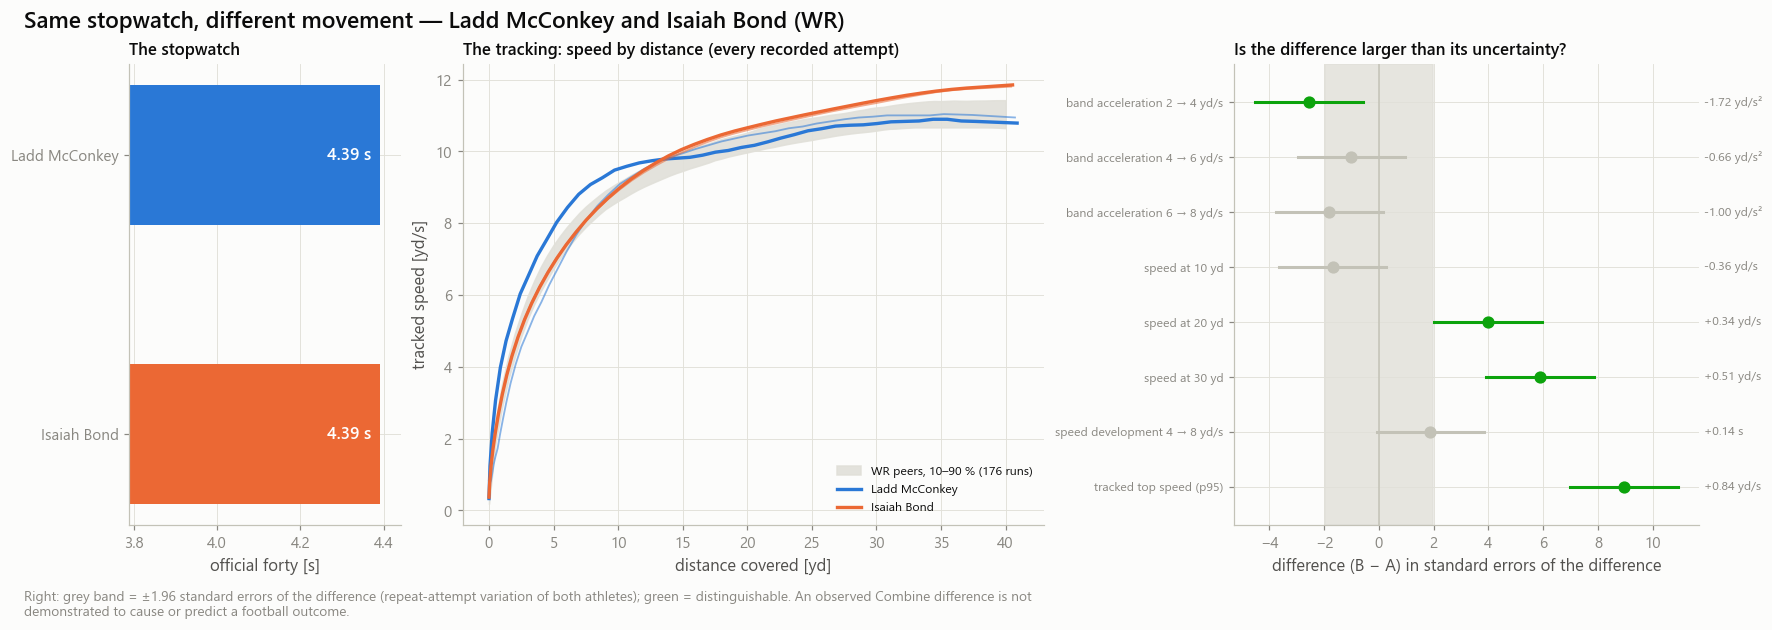

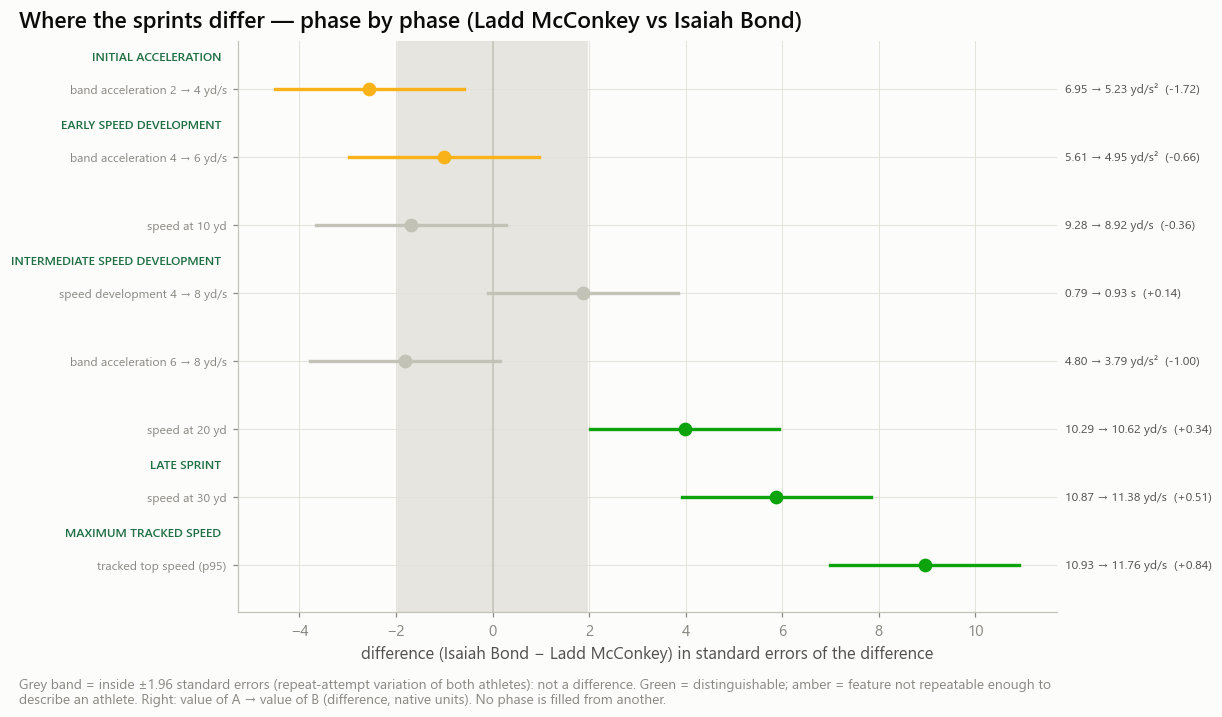

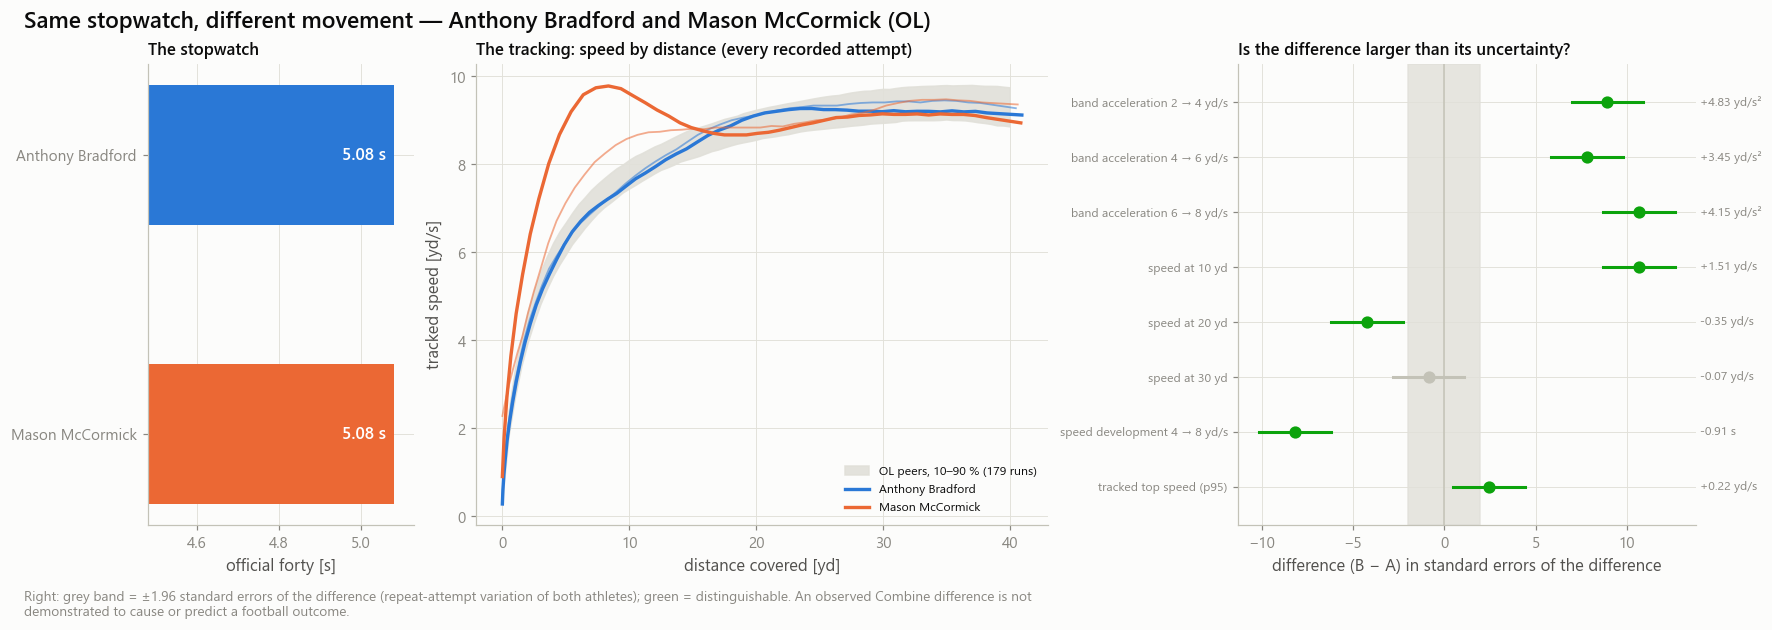

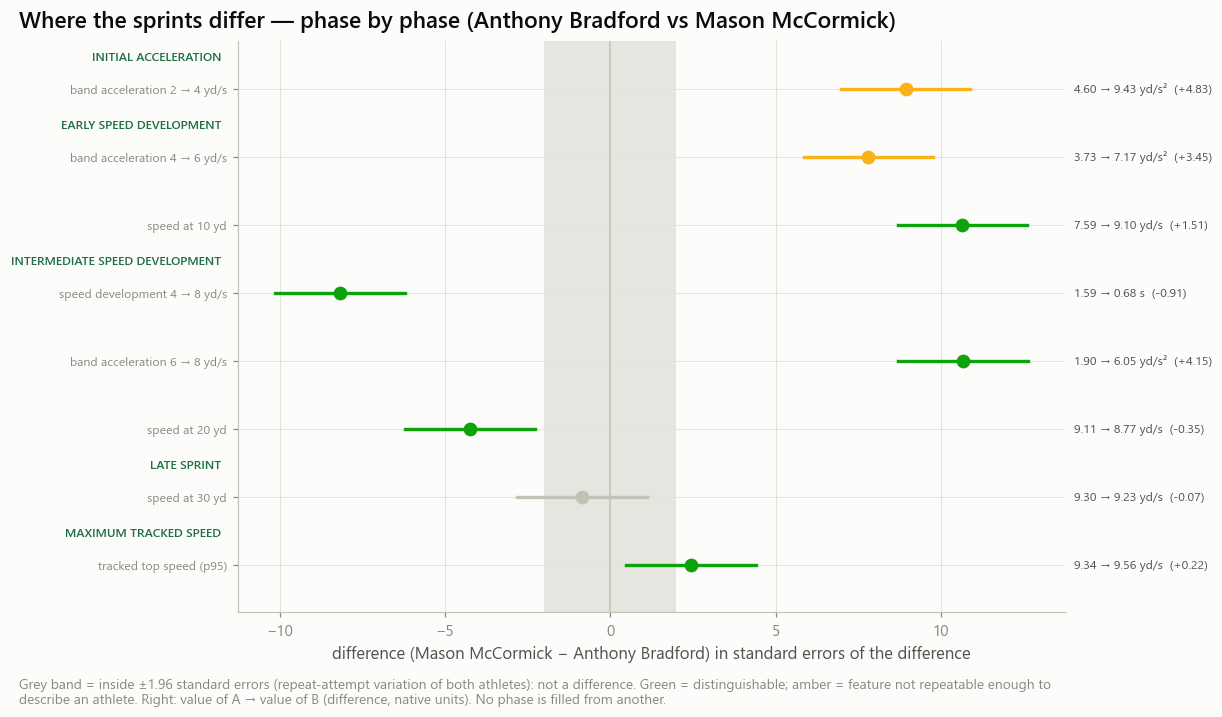

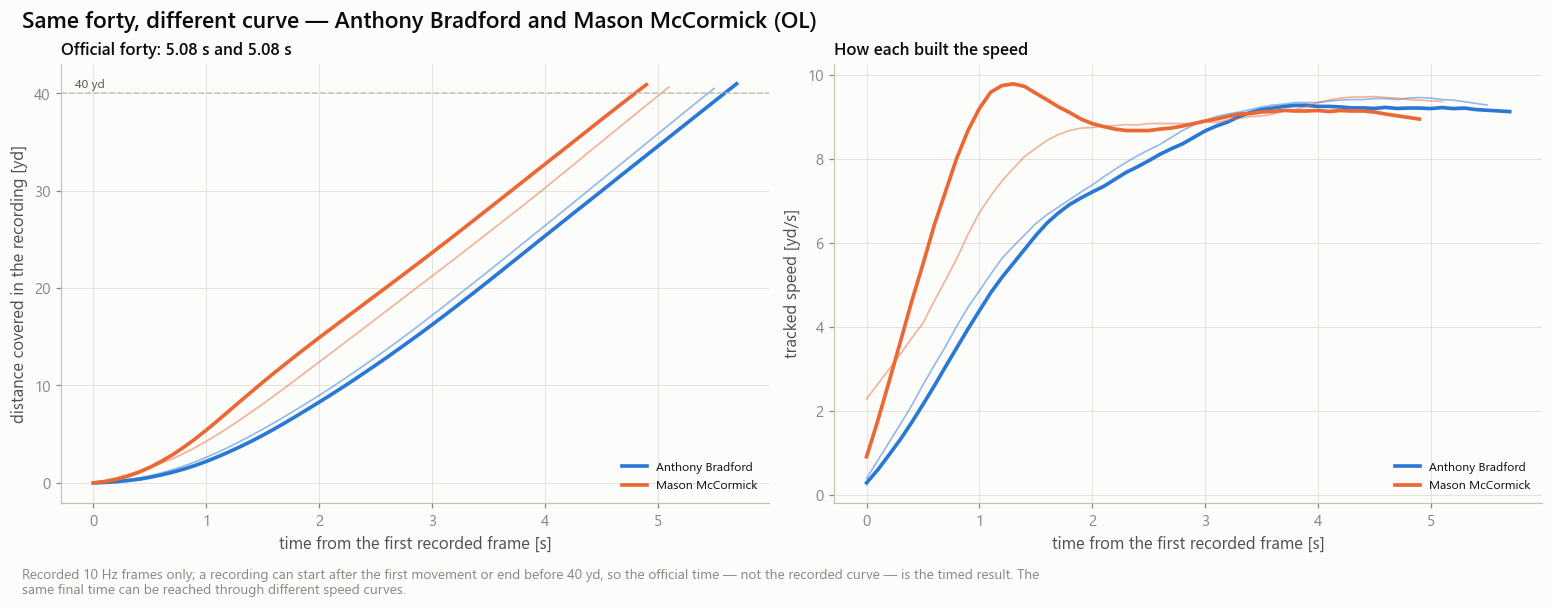

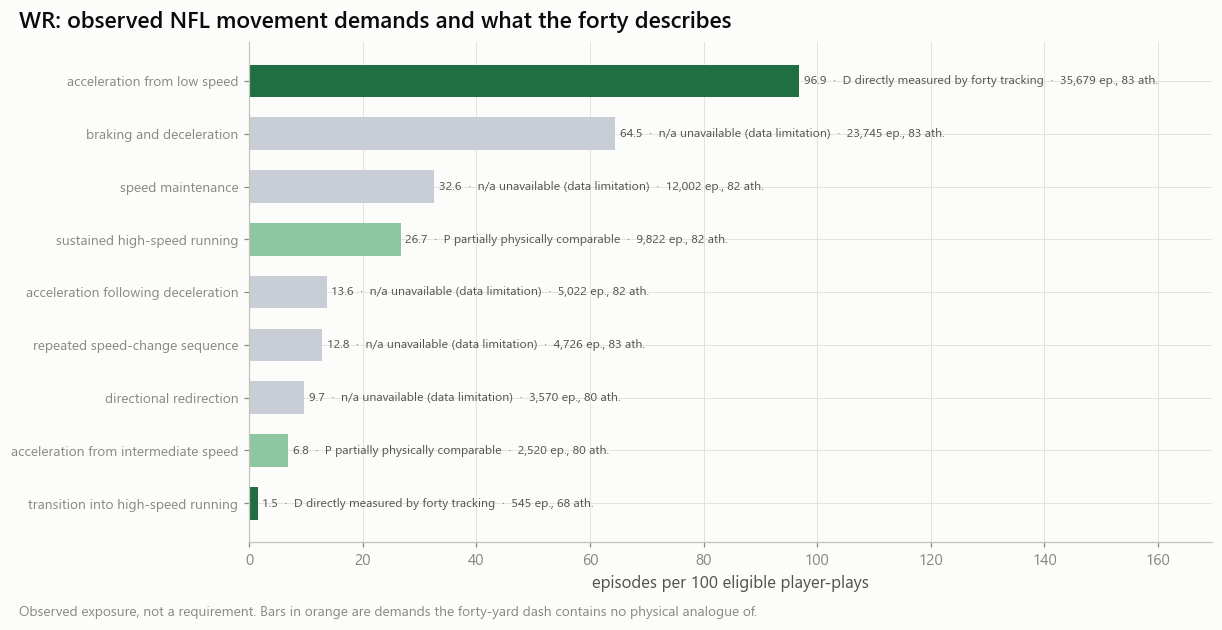

4 comparison card(s) → reports/milestone10/cards


In [6]:
FIGS = {}
for k in ('wr', 'same_forty'):
    s = STORIES.get(k)
    if not s:
        continue
    t = TWD[s['provenance']['pair_id']]
    diffs = BYPAIR.get(t['pair_id'], [])
    names = (t['name_a'], t['name_b'])
    hero = f'AM10B_{k}_01_hero'
    store.show(ifg.fig_twin_story(t, {names[0]: curves(t['nfl_id_a']), names[1]: curves(t['nfl_id_b'])}, band(t['position_group']), diffs), hero, {},
               publication=True, source='application mart: stopwatch_twins, twin_differences, combine_attempt_curves', n='two athletes')
    store.show(ff.fig_phase_decomposition(pk.phase_decomposition(diffs), names), f'AM10B_{k}_02_phases', {}, publication=True, source='twin_differences', n='two athletes')
    if k == 'same_forty':
        store.show(ff.fig_same_finish(t, {names[0]: curves_t(t['nfl_id_a']), names[1]: curves_t(t['nfl_id_b'])}), 'AM10B_same_forty_03_same_finish', {},
                   publication=True, source='combine_attempt_curves', n='every recorded attempt of two athletes')
    FIGS[k] = hero
if STORIES.get('gap'):
    pos = STORIES['gap']['card']['position']
    store.show(ff.fig_gap_position(G, pos), 'AM10B_gap_01_hero', {'gap': pl.DataFrame([r for r in G if r['position_group'] == pos])}, publication=True,
               source='nfl_movement_demands + nfl_demand_registry + movement_matching_summary', n=f'{pos} eligible player-plays')
    FIGS['gap'] = 'AM10B_gap_01_hero'

card_dir = store.reports_dir / 'cards'
card_dir.mkdir(parents=True, exist_ok=True)
EV = list(T['feature_evidence'].iter_rows(named=True))
ids = list(dict.fromkeys(i for k in ('wr', 'same_forty') if STORIES.get(k) for i in (TWD[STORIES[k]['provenance']['pair_id']]['nfl_id_a'],
                                                                                     TWD[STORIES[k]['provenance']['pair_id']]['nfl_id_b'])))
for i in ids:
    mine = []
    for r in T['stopwatch_twins'].filter((pl.col('nfl_id_a') == i) | (pl.col('nfl_id_b') == i)).sort('max_abs_z', descending=True, nulls_last=True).iter_rows(named=True):
        a_is_me = r['nfl_id_a'] == i
        mine.append({**r, 'other_name': r['name_b'] if a_is_me else r['name_a'], 'd_forty': r['d_forty'] if a_is_me else -r['d_forty']})
    met = T['prospect_metrics'].filter(pl.col('nfl_id') == i).sort('feature').to_dicts()
    mat = T['movement_similarity_matrix'].filter(pl.col('nfl_id') == i).to_dicts()
    fig = ifg.fig_intelligence_card(PROF[i], met, mine, mat, curves(i), band(PROF[i]['position_group']), sin.prospect_report(PROF[i], met, mine, mat, EV))
    if controls.save_tables:
        fig.savefig(card_dir / f'intelligence_card_{i}.pdf')
        fig.savefig(card_dir / f'intelligence_card_{i}.png', dpi=200)
    plt.close(fig)
print(f'{len(ids)} comparison card(s) → {cfg.paths.rel(card_dir)}')

## 5 · Write the stories

In [7]:
FILES = {'wr': 'STORY_1_WR_SAME_SPEED_DIFFERENT_DEVELOPMENT.md', 'same_forty': 'STORY_2_SAME_FORTY_DIFFERENT_CURVE.md', 'gap': 'STORY_3_POSITION_MOVEMENT_GAP.md'}
rel = lambda name: os.path.relpath(store.figures_dir / f'{name}.png', OUT).replace(os.sep, '/')
gallery = ['# Signature football stories (executed)', '', f'_Generated {utc_now()} · mart built {MANIFEST["built_at"]} · run mode {controls.run_mode}. '
           'Selected by declared rules; no NFL outcome entered a selection._', '']
for k, fname in FILES.items():
    s = STORIES.get(k)
    md = ss.story_markdown(s, rel(FIGS[k]) if k in FIGS else None) if s else f'## {k}: not available\n\n{SEL[k]}\n'
    gallery += [md, '']
    if controls.save_tables:
        (OUT / fname).write_text(f'# {s["title"] if s else k}\n\n' + md + '\n', encoding='utf-8')
if controls.save_tables:
    (OUT / 'SIGNATURE_STORIES.md').write_text('\n'.join(gallery) + '\n', encoding='utf-8')
    store.write_json('signature_stories', {'finished_at': utc_now(), 'stories': STORIES, 'selection': SEL, 'figures': FIGS, 'cards': ids,
                                           'wr_candidates': WR_CAND[:25], 'provenance': PROV})
print('Send back: the WR candidate table (section 1), the three selection lines, figures AM10B_*, and reports/milestone10/stories/SIGNATURE_STORIES.md.')

Send back: the WR candidate table (section 1), the three selection lines, figures AM10B_*, and reports/milestone10/stories/SIGNATURE_STORIES.md.
